# Tehran House Price Analysis and Prediction with PyTorch

**Project type:** Exploratory Data Analysis (EDA) and deep learning regression  
**Dataset:** `housePrice.csv`  
**Target:** `Price(USD)`  
**Main question:** How well can a simple neural network estimate property prices from area in the Punak neighborhood?

> Educational project only. A model using area as its only input cannot capture all factors that affect a property's price.

## 1. Project objectives

- inspect and validate a tabular real-estate dataset;
- clean malformed area values and handle missing values;
- explore distributions, outliers, and relationships;
- compare Pearson, Spearman, and Kendall correlations;
- prepare a focused dataset for the Punak neighborhood;
- create a reproducible train/validation/test split;
- scale features and target using training data only;
- build and train a regression neural network with PyTorch;
- evaluate it with MAE, RMSE, and R², and compare against a median baseline;
- inspect prediction errors and document limitations.

## 2. Imports and reproducibility

The model is implemented with **PyTorch**. Scikit-learn is used only for splitting the dataset and calculating evaluation metrics.

In [1]:
from pathlib import Path
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Training device: {device}")

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

PyTorch version: 2.11.0+cu130
Training device: cuda


## 3. Load the data

This notebook expects the repository structure shown in the README and is designed to be run from the `notebooks/` directory. If you run it from another working directory, adjust `DATA_PATH`.

In [3]:
DATA_PATH = Path("../data/raw/housePrice.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Run Jupyter from the notebooks/ directory or update DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 3,479 | Columns: 8


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,"1,850,000,000.00","61,666.67"
1,60,1,True,True,True,Shahran,"1,850,000,000.00","61,666.67"
2,79,2,True,True,True,Pardis,"550,000,000.00","18,333.33"
3,95,2,True,True,True,Shahrake Qods,"902,500,000.00","30,083.33"
4,123,2,True,True,True,Shahrake Gharb,"7,000,000,000.00","233,333.33"


## 4. Understand the dataset

Review column types, missing values, duplicates, and summary statistics before changing the data.

In [4]:
display(df_raw.info())
display(df_raw.isna().sum().rename("missing_values").to_frame())
print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")
display(df_raw.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   object 
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   object 
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), object(2)
memory usage: 146.2+ KB


None

,missing_values
Area,0
Room,0
Parking,0
Warehouse,0
Elevator,0
Address,23
Price,0
Price(USD),0


Exact duplicate rows: 208


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area,3479,243,75,111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Room,"3,479.00",NaN,NaN,NaN,2.08,0.76,0.00,2.00,2.00,2.00,5.00
Parking,3479,2,True,2950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Warehouse,3479,2,True,3182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Elevator,3479,2,True,2739,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,3456,192,Punak,161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"3,479.00",NaN,NaN,NaN,"5,359,022,710.58","8,099,934,524.33","3,600,000.00","1,418,250,000.00","2,900,000,000.00","6,000,000,000.00","92,400,000,000.00"
Price(USD),"3,479.00",NaN,NaN,NaN,"178,634.09","269,997.82",120.00,"47,275.00","96,666.67","200,000.00","3,080,000.00"


### Column overview

- `Area`: property area, stored as text in the source file.
- `Room`: number of rooms.
- `Parking`, `Warehouse`, `Elevator`: Boolean property features.
- `Address`: neighborhood/location label.
- `Price`: price in the source currency.
- `Price(USD)`: price expressed in USD in this dataset.

Check the dataset documentation/source before interpreting the currency conversion or redistributing the data.

## 5. Clean and validate the data

Some `Area` values contain commas and are implausibly large for property area. Removing commas and blindly converting them to integers would incorrectly treat values such as `3,310,000,000` as a valid area. We therefore parse the values, flag implausible areas, and exclude those rows from the analysis. The chosen range is a transparent project rule, not a universal real-estate standard.

In [5]:
df = df_raw.copy()

# Parse Area after removing surrounding whitespace and thousands separators.
area_text = df["Area"].astype("string").str.strip().str.replace(",", "", regex=False)
df["Area"] = pd.to_numeric(area_text, errors="coerce")

# Convert the target and source price to numeric, in case the source format changes.
for column in ["Price", "Price(USD)", "Room"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Project-level validity rule: area must be between 20 and 1,000 square meters.
valid_area = df["Area"].between(20, 1000, inclusive="both")
invalid_area_rows = df.loc[~valid_area].copy()

print(f"Rows with invalid or implausible area: {len(invalid_area_rows)}")
display(invalid_area_rows[["Area", "Room", "Address", "Price(USD)"]])

df = df.loc[valid_area].copy()

# Normalize text labels and Boolean-like columns.
df["Address"] = df["Address"].astype("string").str.strip()
for column in ["Parking", "Warehouse", "Elevator"]:
    # The source is already Boolean; this keeps the expected type explicit.
    df[column] = df[column].astype("boolean")

print(f"Rows after area validation: {len(df):,}")
display(df.head())

Rows with invalid or implausible area: 5


,Area,Room,Address,Price(USD)
570,3310000000,2,Ostad Moein,"110,333.33"
709,16160000000,3,Pasdaran,"538,666.67"
1604,8400000000,2,Gheitarieh,"290,000.00"
2171,3600,2,Shahryar,"324,000.00"
2802,2550000000,2,Central Janatabad,"85,000.00"


Rows after area validation: 3,474


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,"1,850,000,000.00","61,666.67"
1,60,1,True,True,True,Shahran,"1,850,000,000.00","61,666.67"
2,79,2,True,True,True,Pardis,"550,000,000.00","18,333.33"
3,95,2,True,True,True,Shahrake Qods,"902,500,000.00","30,083.33"
4,123,2,True,True,True,Shahrake Gharb,"7,000,000,000.00","233,333.33"


### Missing values and duplicates

For this focused analysis, `Area`, `Price(USD)`, and `Address` are essential. Rows missing any of those fields are excluded. Exact duplicate rows are removed before splitting so identical records are less likely to appear in both train and test sets.

In [6]:
required_columns = ["Area", "Price(USD)", "Address"]
before_missing = len(df)
df = df.dropna(subset=required_columns + ["Room"]).copy()
print(f"Rows removed due to missing required values: {before_missing - len(df):,}")

before_duplicates = len(df)
df = df.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {before_duplicates - len(df):,}")

print(f"Final cleaned dataset: {df.shape[0]:,} rows")
display(df.isna().sum().rename("missing_values").to_frame())

Rows removed due to missing required values: 23
Exact duplicate rows removed: 208
Final cleaned dataset: 3,243 rows


,missing_values
Area,0
Room,0
Parking,0
Warehouse,0
Elevator,0
Address,0
Price,0
Price(USD),0


## 6. Exploratory data analysis

### Numeric distributions

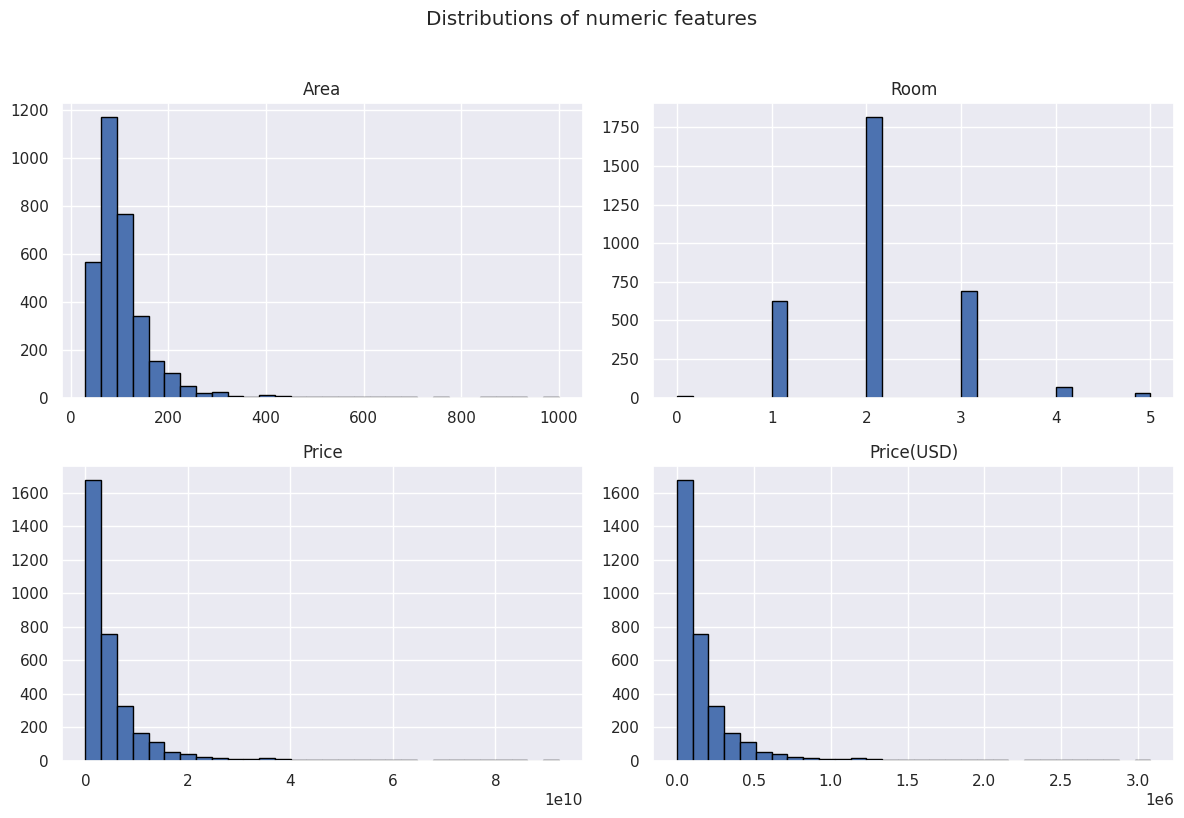

In [7]:
numeric_columns = ["Area", "Room", "Price", "Price(USD)"]
df[numeric_columns].hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout()
plt.show()

### Price versus area

Real-estate prices often have a skewed distribution. Inspect the scatter plot before fitting a model, and remember that this view does not establish causation.

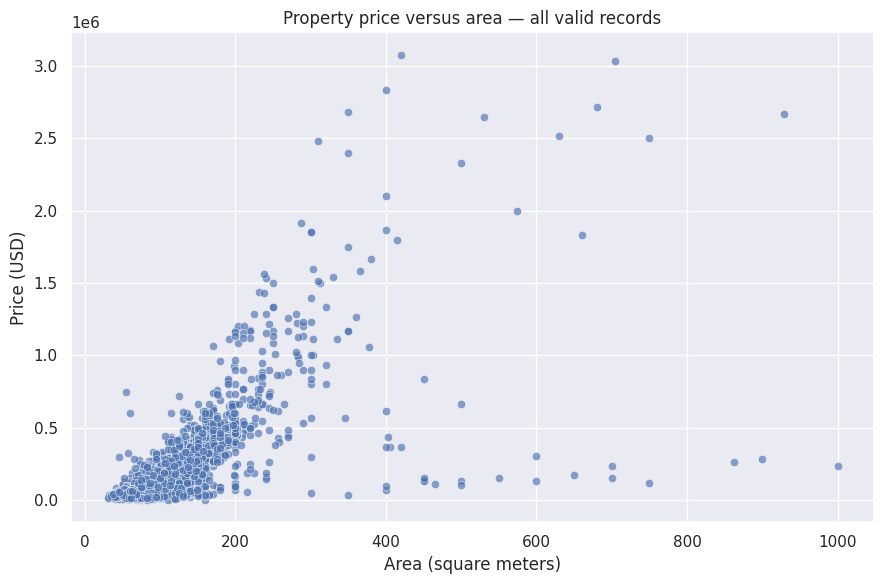

In [8]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Area", y="Price(USD)", alpha=0.65)
plt.title("Property price versus area — all valid records")
plt.xlabel("Area (square meters)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()

### Correlation methods

Pearson measures linear association; Spearman and Kendall use ranks and can better describe monotonic relationships when a relationship is not linear. Correlation does not imply causation, and these correlations are descriptive rather than a model evaluation.

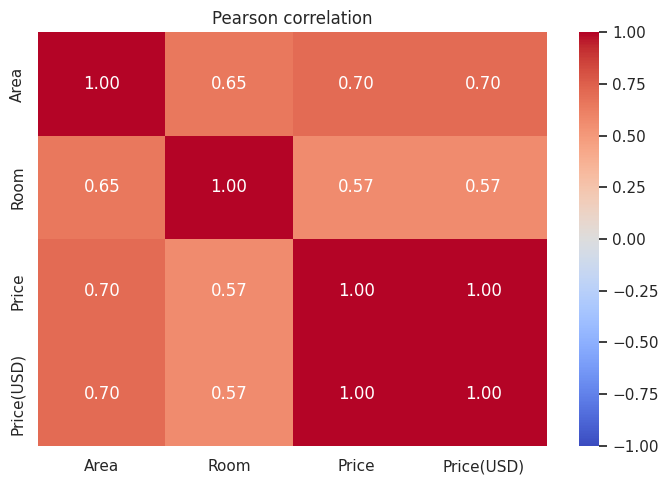

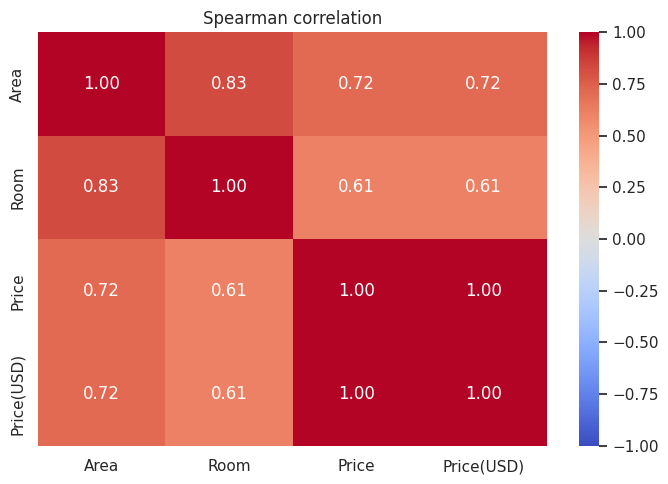

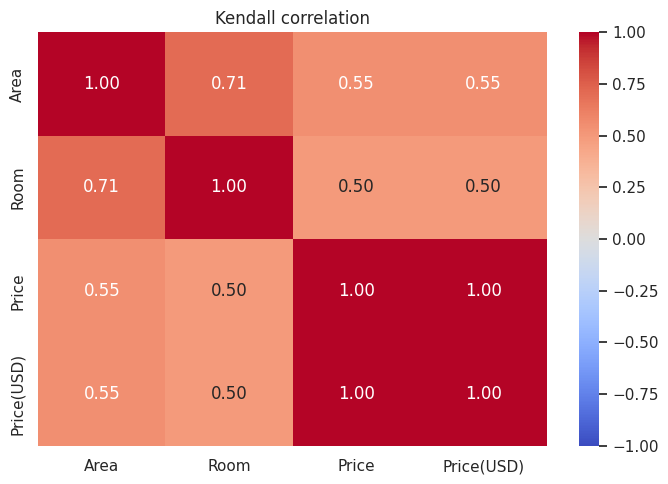

In [9]:
corr_columns = ["Area", "Room", "Price", "Price(USD)"]
for method in ["pearson", "spearman", "kendall"]:
    corr = df[corr_columns].corr(method=method)
    plt.figure(figsize=(7, 5))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
    plt.title(f"{method.title()} correlation")
    plt.tight_layout()
    plt.show()

### Neighborhood coverage

The full dataset contains several neighborhoods. This project focuses the prediction task on Punak to avoid treating location differences as if they were explained by area alone.

In [10]:
display(df["Address"].value_counts().head(15).rename_axis("Address").to_frame("count"))

,count
Address,
Punak,148
West Ferdows Boulevard,133
Gheitarieh,132
Pardis,123
Shahran,123
Saadat Abad,120
Parand,119
Shahr-e-Ziba,91
Jeyhoon,88


## 7. Focus the modeling task on Punak

We use one input feature (`Area`) and one target (`Price(USD)`). This makes the project an interpretable baseline, but it deliberately ignores room count, amenities, building age, exact location, and other potentially important variables.

In [11]:
TARGET_ADDRESS = "Punak"
df_punak = df.loc[df["Address"].str.casefold() == TARGET_ADDRESS.casefold()].copy()

if len(df_punak) < 10:
    raise ValueError(
        f"Only {len(df_punak)} valid records found for {TARGET_ADDRESS}; "
        "check the Address values and dataset."
    )

df_punak = df_punak.drop_duplicates(subset=["Area", "Price(USD)", "Room", "Parking", "Warehouse", "Elevator", "Address"])
print(f"Unique Punak records used: {len(df_punak):,}")
display(df_punak.head())
display(df_punak[["Area", "Price(USD)"]].describe())

Unique Punak records used: 148


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
54,61,1,True,True,False,Punak,"2,030,000,000.00","67,666.67"
61,67,2,True,True,True,Punak,"2,800,000,000.00","93,333.33"
62,72,2,True,True,False,Punak,"2,200,000,000.00","73,333.33"
63,63,1,True,True,False,Punak,"2,200,000,000.00","73,333.33"
64,75,2,True,True,False,Punak,"2,200,000,000.00","73,333.33"


,Area,Price(USD)
count,148.00,148.00
mean,85.30,"125,566.89"
std,29.45,"67,048.46"
min,47.00,"58,333.33"
25%,65.00,"76,666.67"
50%,75.00,"99,666.67"
75%,95.25,"142,083.34"
max,190.00,"380,000.00"


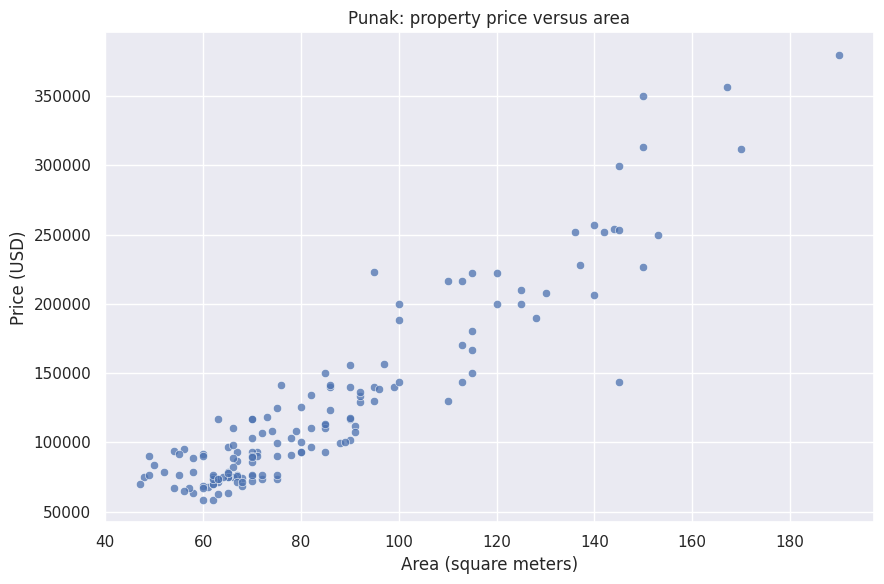

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_punak, x="Area", y="Price(USD)", alpha=0.75)
plt.title("Punak: property price versus area")
plt.xlabel("Area (square meters)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()

## 8. Train, validation, and test split

The test set is held out for final evaluation. A validation set is split from the training portion and used to select the best epoch. Feature and target scaling statistics are calculated from the training set only to avoid data leakage.

In [13]:
X = df_punak[["Area"]].to_numpy(dtype=np.float32)
y = df_punak[["Price(USD)"]].to_numpy(dtype=np.float32)

# First reserve the final test set.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Split the remaining data into training and validation sets.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE
)

# Standardize using training-set statistics only.
x_mean, x_std = X_train.mean(axis=0), X_train.std(axis=0)
y_mean, y_std = y_train.mean(axis=0), y_train.std(axis=0)

# Avoid division by zero in case a feature has no variation.
x_std = np.where(x_std == 0, 1.0, x_std)
y_std = np.where(y_std == 0, 1.0, y_std)

X_train_scaled = (X_train - x_mean) / x_std
X_val_scaled = (X_val - x_mean) / x_std
X_test_scaled = (X_test - x_mean) / x_std

y_train_scaled = (y_train - y_mean) / y_std
y_val_scaled = (y_val - y_mean) / y_std
y_test_scaled = (y_test - y_mean) / y_std

def to_tensor(array):
    return torch.tensor(array, dtype=torch.float32)

train_dataset = TensorDataset(to_tensor(X_train_scaled), to_tensor(y_train_scaled))
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

X_val_tensor = to_tensor(X_val_scaled).to(device)
y_val_tensor = to_tensor(y_val_scaled).to(device)
X_test_tensor = to_tensor(X_test_scaled).to(device)

print(f"Training rows:   {len(X_train)}")
print(f"Validation rows: {len(X_val)}")
print(f"Test rows:       {len(X_test)}")

Training rows:   94
Validation rows: 24
Test rows:       30


## 9. Build a PyTorch regression model

The neural network takes one input (`Area`) and returns one standardized price estimate. Because this is a small tabular dataset, the network is intentionally small. A more complex model is not automatically better.

In [14]:
class HousePriceRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

model = HousePriceRegressor().to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)

print(model)

HousePriceRegressor(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


## 10. Train the model

We use mean squared error as the training loss and Adam as the optimizer. The best model state is selected using validation loss, and early stopping limits unnecessary training. The final test set is not used during training.

In [15]:
EPOCHS = 500
PATIENCE = 40

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        predictions_batch = model(batch_X)
        loss = loss_fn(predictions_batch, batch_y)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * len(batch_X)

    train_loss = running_train_loss / len(train_dataset)

    model.eval()
    with torch.no_grad():
        val_predictions = model(X_val_tensor)
        val_loss = loss_fn(val_predictions, y_val_tensor).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch + 1:03d}/{EPOCHS}] "
            f"Train loss: {train_loss:.4f} | Validation loss: {val_loss:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

model.load_state_dict(best_state)
print(f"Best validation loss (standardized target): {best_val_loss:.4f}")

Epoch [050/500] Train loss: 0.1692 | Validation loss: 0.0891
Epoch [100/500] Train loss: 0.1553 | Validation loss: 0.0844
Epoch [150/500] Train loss: 0.1561 | Validation loss: 0.0723
Epoch [200/500] Train loss: 0.1580 | Validation loss: 0.0816
Early stopping at epoch 208.
Best validation loss (standardized target): 0.0712


## 11. Evaluate the model on the held-out test set

Predictions are transformed back to USD before computing metrics. We compare the neural network with a simple baseline that predicts the median price from the training data.

In [16]:
model.eval()
with torch.no_grad():
    test_predictions_scaled = model(X_test_tensor).cpu().numpy()

y_pred = test_predictions_scaled * y_std + y_mean
y_test_original = y_test.reshape(-1)
y_pred_original = y_pred.reshape(-1)

median_baseline = np.full(shape=len(y_test_original), fill_value=float(np.median(y_train)))

def regression_metrics(y_true, y_hat):
    return {
        "MAE (USD)": mean_absolute_error(y_true, y_hat),
        "RMSE (USD)": np.sqrt(mean_squared_error(y_true, y_hat)),
        "R²": r2_score(y_true, y_hat),
    }

results = pd.DataFrame({
    "PyTorch neural network": regression_metrics(y_test_original, y_pred_original),
    "Median baseline": regression_metrics(y_test_original, median_baseline),
}).T.sort_values("MAE (USD)")

display(results)

,MAE (USD),RMSE (USD),R²
PyTorch neural network,"16,443.04","20,010.32",0.89
Median baseline,"39,951.11","62,933.88",-0.10


## 12. Training curves and prediction diagnostics

Training and validation losses are shown in standardized-target units. The actual-versus-predicted and residual plots use USD.

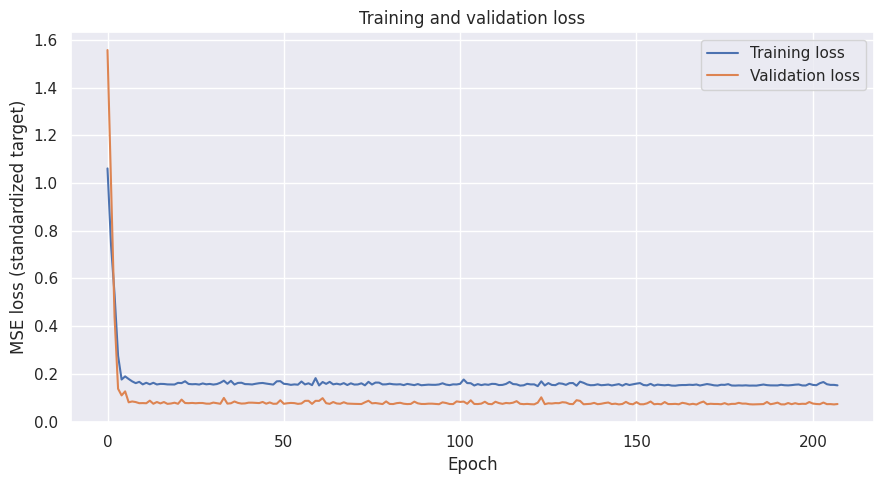

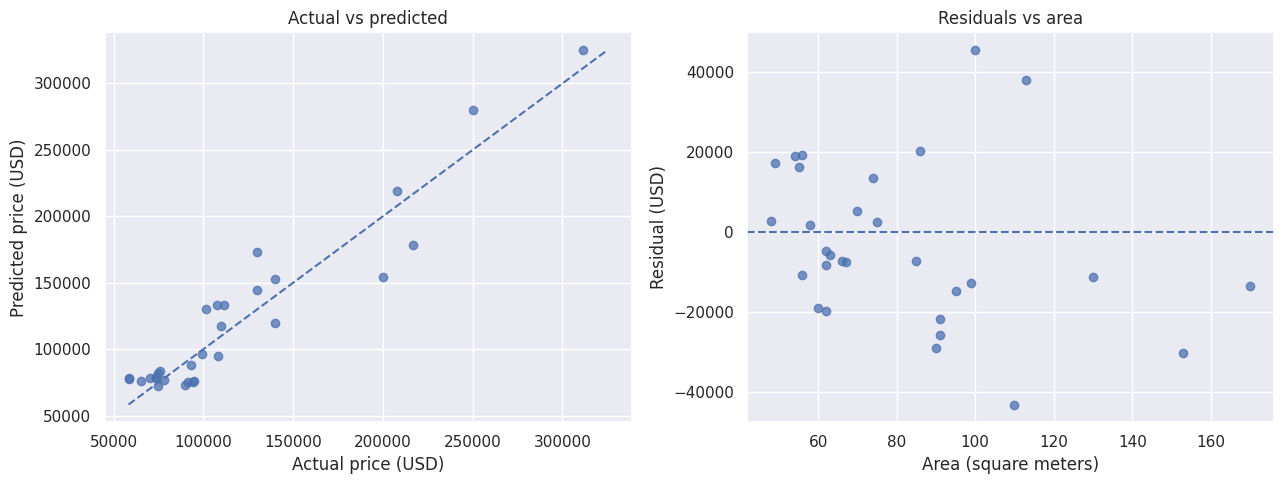

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (standardized target)")
plt.title("Training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test_original, y_pred_original, alpha=0.75)
min_value = min(float(y_test_original.min()), float(y_pred_original.min()))
max_value = max(float(y_test_original.max()), float(y_pred_original.max()))
axes[0].plot([min_value, max_value], [min_value, max_value], linestyle="--")
axes[0].set_title("Actual vs predicted")
axes[0].set_xlabel("Actual price (USD)")
axes[0].set_ylabel("Predicted price (USD)")

residuals = y_test_original - y_pred_original
axes[1].scatter(X_test.reshape(-1), residuals, alpha=0.75)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs area")
axes[1].set_xlabel("Area (square meters)")
axes[1].set_ylabel("Residual (USD)")

plt.tight_layout()
plt.show()

## 13. Inspect predictions and errors

The neural network is nonlinear, so there is no single coefficient that can be interpreted as a constant USD change per square meter. Instead, inspect individual predictions and residuals.

In [18]:
comparison = pd.DataFrame({
    "Area (m²)": X_test.reshape(-1),
    "Actual price (USD)": y_test_original,
    "Predicted price (USD)": y_pred_original,
    "Residual (USD)": residuals,
})
display(comparison.sort_values("Area (m²)").head(15))

,Area (m²),Actual price (USD),Predicted price (USD),Residual (USD)
20,48.00,"75,000.00","72,136.85","2,863.15"
8,49.00,"89,800.00","72,672.26","17,127.74"
0,54.00,"94,000.00","74,989.76","19,010.24"
2,55.00,"91,666.67","75,389.09","16,277.58"
17,56.00,"95,000.00","75,788.43","19,211.57"
24,56.00,"65,000.00","75,788.43","-10,788.43"
27,58.00,"78,333.33","76,587.10","1,746.23"
29,60.00,"58,333.33","77,384.19","-19,050.86"
23,62.00,"58,333.33","78,179.95","-19,846.62"
18,62.00,"70,000.00","78,179.95","-8,179.95"


## 14. Try a prediction

Enter a positive area. Predictions outside the training-area range are extrapolations and may be unreliable.

In [19]:
min_area = float(X_train.min())
max_area = float(X_train.max())
print(f"Training area range: {min_area:g}–{max_area:g} m²")

area_input = 100.0  # Change this value to experiment.
if area_input <= 0:
    raise ValueError("Area must be positive.")
if not (min_area <= area_input <= max_area):
    warnings.warn("This area is outside the training range; prediction is extrapolation.")

new_area_scaled = (np.array([[area_input]], dtype=np.float32) - x_mean) / x_std
new_area_tensor = to_tensor(new_area_scaled).to(device)

model.eval()
with torch.no_grad():
    predicted_scaled = model(new_area_tensor).cpu().numpy()

predicted_price = float((predicted_scaled * y_std + y_mean).item())
print(f"Estimated price for {area_input:g} m² in Punak: ${predicted_price:,.2f}")

Training area range: 47–167 m²
Estimated price for 100 m² in Punak: $154,551.59


## 15. Conclusions and limitations

Write your conclusions after running the notebook and reviewing the metric values and plots. Do not claim that the neural network is accurate unless held-out results support that conclusion.

Important limitations:

1. The model uses only area; property prices also depend on location, room count, amenities, age, condition, and market timing.
2. The dataset's origin, collection date, and currency-conversion methodology should be verified and documented.
3. The area validity range (20–1,000 m²) is a project assumption, not a universal standard.
4. A random split is a useful teaching baseline, but it does not test how well the model generalizes to future market conditions.
5. This educational model should not be used as a professional valuation.

### Suggested next steps

- compare the neural network with a linear regression baseline;
- add room count and property amenities as input features;
- use cross-validation or repeated splits to estimate stability;
- evaluate results across neighborhoods;
- document the dataset source and licensing before publishing it.